# Step 3: feature engineering

Run in Google Colab with train and validation under BT4222 Shared Final Folder/train_val/, the shared articles.parquet beside those folders, and the test files under BT4222 Shared Final Folder/test/. This notebook builds one row per impression-candidate article for train, validation, and test. It fits vocabularies on train, aggregates fixed history into one profile per user before joining it to candidates, and streams output batches to Parquet.

The output keeps identifiers and the click label for evaluation, plus baseline, behavior, article, history, and cross features. There are no log transforms. Nominal device, category, article type, and premium-subscriber fields are one-hot encoded using train-fitted vocabularies. Per-category, per-topic, and per-article-type history preferences are numeric fractions. Run cells from top to bottom. Requires pandas, numpy, pyarrow, and Google Colab Drive access.
For the labelled holdout update, rebuild only test outputs using the existing train-fitted vocabulary and transformations. Train and validation files stay unchanged. Run the updated Step 1 first.


## Feature groups

| Group | Output features |
| --- | --- |
| Baseline | User/impression/candidate keys, click label, device, subscriber flags, front-page flag, hour, weekday, slate size, article category/type/premium, article age, and fixed-history summaries |
| Behavior | Weekend indicator |
| Article | Body word count, topic count, 24-hour eligibility, and age relative to the eligible slate median |
| History profile | Fraction of historical clicks in every train-known category and article type; fraction of clicked articles containing every train-known topic; median body word count; median valid read time; mean observed scroll; history size |
| Additional | Seven-day history clicks, category affinity with 72-hour decay, recent-topic Jaccard, same-category mean raw read time, candidate-to-profile preference matches, and premium/subscriber interaction |
| Encoding | Train-fitted one-hot indicators for device, category, article type, and premium/subscriber combination; missing and unknown indicators |

History fractions and one-hot column names use numeric suffixes. The feature_vocabulary.json file maps each suffix to its source value. All read-time, history-size, article-age, and article-length values stay on their raw scale.

## 0. Paths and settings

Train and validation behaviors/history come from the train and validation folders inside BT4222 Shared Final Folder/train_val/. The shared article catalogue is train_val/articles.parquet. Project test behaviors/history come from unused original validation users and remain under BT4222 Shared Final Folder/test/. Their click labels are reserved for final evaluation. An article catalogue from EB-NeRD testset is included when available so test-only articles can receive metadata.

In [ ]:
from bisect import bisect_left
from collections import Counter, defaultdict
import json
import math
import os
import statistics
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

COLAB_ROOT = Path("/content/drive/MyDrive/Colab Notebooks")
SHARED_ROOT = COLAB_ROOT / "BT4222 Shared"
FINAL_ROOT = COLAB_ROOT / "BT4222 Shared Final Folder"
TRAIN_VAL_ROOT = FINAL_ROOT / "train_val"
TESTSET_ROOT = SHARED_ROOT / "ebnerd_testset"
OUTPUT_ROOT = FINAL_ROOT / "feature_engineering"
STATE_PATH = OUTPUT_ROOT / "feature_vocabulary.json"

BATCH_SIZE = 500             # behavior rows per batch; candidates expand from these
OVERWRITE = True              # replace the new holdout outputs only
REBUILD_SPLITS = ("test",)

def first_existing(paths):
    return next((path for path in paths if path.is_file()), None)

def behavior_file(folder):
    path = first_existing([
        folder / "behaviours.parquet",
        folder / "behaviors.parquet",
    ])
    if path is None:
        raise FileNotFoundError(f"Behavior file not found in {folder}")
    return path

SPLITS = {
    "train": {
        "behaviors": behavior_file(TRAIN_VAL_ROOT / "train"),
        "history": TRAIN_VAL_ROOT / "train" / "history.parquet",
        "label_mode": "required",
    },
    "validation": {
        "behaviors": behavior_file(TRAIN_VAL_ROOT / "validation"),
        "history": TRAIN_VAL_ROOT / "validation" / "history.parquet",
        "label_mode": "required",
    },
    "test": {
        "behaviors": behavior_file(FINAL_ROOT / "test"),
        "history": FINAL_ROOT / "test" / "history.parquet",
        "label_mode": "required",
    },
}
for split, paths in SPLITS.items():
    for kind in ("behaviors", "history"):
        if not paths[kind].is_file():
            raise FileNotFoundError(f"{split} {kind} file not found: {paths[kind]}")

ARTICLE_PATHS = [TRAIN_VAL_ROOT / "articles.parquet"]
for candidate in (
    FINAL_ROOT / "test" / "articles.parquet",
    TESTSET_ROOT / "articles.parquet",
    TESTSET_ROOT / "test" / "articles.parquet",
):
    if candidate.is_file():
        ARTICLE_PATHS.append(candidate)
        break
if not ARTICLE_PATHS[0].is_file():
    raise FileNotFoundError(f"Article catalogue not found: {ARTICLE_PATHS[0]}")
for split, paths in SPLITS.items():
    print(f"{split}: {paths['behaviors']} | {paths['history']}")
print("Article catalogues:", [str(path) for path in ARTICLE_PATHS])
print("Outputs:", OUTPUT_ROOT)
SPLIT_MANIFEST = json.loads((FINAL_ROOT / "split_manifest.json").read_text())
if SPLIT_MANIFEST.get("protocol") != "ebnerd_small_labelled_user_holdout_v1":
    raise ValueError("Run the updated Step 1 before rebuilding holdout features.")


## 1. Shared helpers and article metadata

The raw body text is used only to count words, then discarded. Missing bodies have a missing word count. Fixed history preferences later use the article category, type, topics, and this word count.

In [29]:
def as_sequence(value):
    if value is None or value is pd.NA or (isinstance(value, (float, np.floating)) and math.isnan(value)):
        return ()
    if isinstance(value, (list, tuple, np.ndarray)):
        return tuple(value)
    raise TypeError(f"Expected a list-like field, got {type(value).__name__}")

def nominal(value):
    if value is None or value is pd.NA or (isinstance(value, (float, np.floating)) and math.isnan(value)):
        return None
    return str(value)

def optional_bool(value):
    if value is None or pd.isna(value):
        return None
    return bool(value)

def valid_number(value, upper=None):
    if value is None:
        return None
    try:
        number = float(value)
    except (TypeError, ValueError):
        return None
    if not math.isfinite(number) or number < 0 or (upper is not None and number > upper):
        return None
    return number

def body_word_count(value):
    if not isinstance(value, str) or not value.strip():
        return None
    return len(value.split())

def load_article_features(paths):
    frames = []
    needed = [
        "article_id", "category", "article_type", "premium",
        "published_time", "topics", "body",
    ]
    for path in paths:
        available = set(pq.ParquetFile(path).schema_arrow.names)
        missing = set(needed) - available
        if missing:
            raise ValueError(f"{path} is missing article columns: {sorted(missing)}")
        part = pd.read_parquet(path, columns=needed)
        part["category"] = part["category"].map(nominal)
        part["article_type"] = part["article_type"].map(nominal)
        part["premium"] = part["premium"].map(optional_bool)
        part["published_time"] = pd.to_datetime(part["published_time"])
        part["topics"] = part["topics"].map(
            lambda value: tuple(dict.fromkeys(
                str(topic) for topic in as_sequence(value) if topic is not None and not pd.isna(topic)
            ))
        )
        part["topic_count"] = part["topics"].map(len).astype("int32")
        part["body_word_count"] = part["body"].map(body_word_count)
        part["_article_found"] = True
        frames.append(part.drop(columns="body"))
    articles = (
        pd.concat(frames, ignore_index=True)
        .drop_duplicates("article_id", keep="first")
        .set_index("article_id", verify_integrity=True)
    )
    article_lookup = articles.to_dict(orient="index")
    return articles, article_lookup

## 2. Baseline candidate rows and joins

Expand each behavior row into its candidate slate, then attach article metadata and the precomputed user history profile. The pair (user_id, impression_id) identifies an impression: the test data reuses some impression IDs across users. Read-time and scroll fields from behaviors are omitted because they describe outcomes after the impression.

In [30]:
BASELINE_COLUMNS = [
    "split", "user_id", "impression_id", "candidate_article_id",
    "current_page_article_id", "impression_time", "clicked",
    "device_type", "is_sso_user", "is_subscriber", "is_front_page",
    "hour", "day_of_week", "slate_size",
]

def extract_baseline_features(behavior_rows, split, label_mode):
    rows = []
    for behavior in behavior_rows:
        candidates = tuple(int(value) for value in as_sequence(behavior["article_ids_inview"]))
        if not candidates or len(candidates) != len(set(candidates)):
            raise ValueError("A behavior has an empty or duplicate candidate slate")
        time = pd.Timestamp(behavior["impression_time"])
        if pd.isna(time):
            raise ValueError("A behavior has no impression time")
        raw_page = behavior.get("article_id")
        page_id = None if raw_page is None or pd.isna(raw_page) else int(raw_page)
        raw_clicks = behavior.get("article_ids_clicked")
        if label_mode == "required" and raw_clicks is None:
            raise ValueError("A labeled behavior has no article_ids_clicked")
        clicked_ids = (
            {int(value) for value in as_sequence(raw_clicks)}
            if label_mode == "required" else None
        )
        for article_id in candidates:
            rows.append({
                "split": split,
                "user_id": int(behavior["user_id"]),
                "impression_id": int(behavior["impression_id"]),
                "candidate_article_id": article_id,
                "current_page_article_id": page_id,
                "impression_time": time,
                "clicked": int(article_id in clicked_ids) if clicked_ids is not None else None,
                "device_type": nominal(behavior.get("device_type")),
                "is_sso_user": optional_bool(behavior.get("is_sso_user")),
                "is_subscriber": optional_bool(behavior.get("is_subscriber")),
                "is_front_page": page_id is None,
                "hour": time.hour,
                "day_of_week": time.dayofweek,
                "slate_size": len(candidates),
            })
    return pd.DataFrame.from_records(rows, columns=BASELINE_COLUMNS)

def assemble_baseline_features(behavior_rows, split, label_mode, article_table, profile_index):
    frame = extract_baseline_features(behavior_rows, split, label_mode)
    if frame.empty:
        return frame
    frame = frame.join(article_table, on="candidate_article_id", how="left")
    frame = frame.join(profile_index, on="user_id", how="left")
    return frame

## 3. Engineered features from behaviors

Position and calendar features use only information available at impression time.

In [31]:
def engineer_behavior_features(frame):
    frame = frame.copy()
    frame["is_weekend"] = frame["day_of_week"].ge(5)
    return frame

## 4. Engineered features from articles

With article metadata joined in the baseline stage, calculate article age, topic count, body length, 24-hour eligibility, and age relative to the median eligible article in that user-impression slate. Missing or future-published articles receive a missing age.

In [32]:
def engineer_article_features(frame):
    frame["_article_found"] = (
        frame["_article_found"].fillna(False).astype(bool)
    )
    frame["topic_count"] = frame["topic_count"].fillna(0).astype("int32")
    frame["has_topics"] = frame["topic_count"].gt(0)
    frame["body_word_count"] = frame["body_word_count"].astype("Int32")

    age = (
        pd.to_datetime(frame["impression_time"]) - pd.to_datetime(frame["published_time"])
    ).dt.total_seconds() / 3600.0
    frame["article_age_h"] = age.where(age.ge(0))
    frame["article_age_missing"] = frame["article_age_h"].isna()
    frame["is_24h_eligible"] = frame["article_age_h"].between(0, 24, inclusive="both")
    eligible_age = frame["article_age_h"].where(frame["is_24h_eligible"])
    median_age = eligible_age.groupby(
        [frame["user_id"], frame["impression_id"]], sort=False
    ).transform("median")
    frame["slate_relative_age_h"] = (
        frame["article_age_h"] - median_age
    ).where(frame["is_24h_eligible"])
    return frame

## 5. Train-fitted categorical vocabulary

Scan train candidate articles and train fixed history articles. The saved JSON maps stable numbered columns to category, topic, article-type, and device values. Validation and test reuse it; unseen nominal values activate an unknown indicator.

In [33]:
ONEHOT_FIELDS = ("device_type", "category", "article_type", "premium_subscriber")
PREFERENCE_FIELDS = {
    "category": "hist_category_frac",
    "topics": "hist_topic_frac",
    "article_type": "hist_article_type_frac",
}

def fit_vocabulary(train_behavior_path, train_history_path, article_lookup):
    device_values = set()
    used_article_ids = set()
    parquet = pq.ParquetFile(train_behavior_path)
    for batch in parquet.iter_batches(
        batch_size=BATCH_SIZE, columns=["device_type", "article_ids_inview"]
    ):
        for row in batch.to_pylist():
            device = nominal(row.get("device_type"))
            if device is not None:
                device_values.add(device)
            used_article_ids.update(int(value) for value in as_sequence(row["article_ids_inview"]))
    history_ids = pd.read_parquet(train_history_path, columns=["article_id_fixed"])
    for values in history_ids["article_id_fixed"]:
        used_article_ids.update(int(value) for value in as_sequence(values))

    categories, article_types, topics = set(), set(), set()
    for article_id in used_article_ids:
        article = article_lookup.get(article_id)
        if article is None:
            continue
        category = nominal(article["category"])
        article_type = nominal(article["article_type"])
        if category is not None:
            categories.add(category)
        if article_type is not None:
            article_types.add(article_type)
        topics.update(article["topics"])
    return {
        "version": 1,
        "device_type": sorted(device_values),
        "category": sorted(categories),
        "article_type": sorted(article_types),
        "topics": sorted(topics),
        "premium_subscriber": [
            "premium_subscriber", "premium_non_subscriber",
            "standard_subscriber", "standard_non_subscriber",
        ],
    }

def preference_columns(state):
    columns = []
    for field, prefix in PREFERENCE_FIELDS.items():
        columns.extend(f"{prefix}_{i:03d}" for i in range(len(state[field])))
        columns.append(f"{prefix}_other")
    return columns

def onehot_columns(state):
    columns = []
    for field in ONEHOT_FIELDS:
        columns.extend(f"ohe_{field}_{i:03d}" for i in range(len(state[field])))
        columns.extend((f"ohe_{field}_missing", f"ohe_{field}_unknown"))
    return columns

## 6. Engineer fixed history before the candidate join

Each history row becomes one numeric profile per user. Preference denominators are that user's total valid historical click events. A clicked article can have several topics, so topic fractions need not sum to one. Missing article metadata contributes to history size but not to known category, topic, or type counts. Valid read times are finite and nonnegative; valid scroll depths are from 0 to 100. The profile table is saved separately for inspection.

In [34]:
HISTORY_SCALARS = [
    "user_id", "history_size",
    "median_history_body_word_count", "median_history_read_time",
    "mean_history_scroll_percentage",
]

def aggregate_history_features(history_path, article_lookup, state, split_start):
    history = pd.read_parquet(history_path, columns=[
        "user_id", "article_id_fixed", "impression_time_fixed",
        "read_time_fixed", "scroll_percentage_fixed",
    ])
    if history["user_id"].duplicated().any():
        raise ValueError(f"History has duplicate user IDs: {history_path}")
    category_vocab = set(state["category"])
    topic_vocab = set(state["topics"])
    type_vocab = set(state["article_type"])
    rows, metadata = [], {}

    for user in history.itertuples(index=False):
        ids = as_sequence(user.article_id_fixed)
        times = as_sequence(user.impression_time_fixed)
        reads = as_sequence(user.read_time_fixed)
        scrolls = as_sequence(user.scroll_percentage_fixed)
        if len({len(ids), len(times), len(reads), len(scrolls)}) != 1:
            raise ValueError(f"Misaligned fixed history arrays for user {user.user_id}")

        events = []
        for article_id, raw_time, raw_read, raw_scroll in zip(ids, times, reads, scrolls):
            if raw_time is None or pd.isna(raw_time):
                continue
            time = pd.Timestamp(raw_time)
            if time >= split_start:
                raise ValueError(f"History reaches behavior period for user {user.user_id}")
            events.append((
                time, int(article_id), valid_number(raw_read),
                valid_number(raw_scroll, upper=100),
            ))
        events.sort(key=lambda event: event[0])
        size = len(events)
        categories, topics, article_types = Counter(), Counter(), Counter()
        category_weight = defaultdict(float)
        category_reads = defaultdict(list)
        body_lengths, read_times, observed_scrolls = [], [], []
        latest = events[-1][0] if events else None
        last5_topics = []

        for time, article_id, read, scroll in events:
            article = article_lookup.get(article_id)
            if read is not None:
                read_times.append(read)
            if scroll is not None:
                observed_scrolls.append(scroll)
            if article is None:
                continue
            category = nominal(article["category"])
            article_type = nominal(article["article_type"])
            if category is not None:
                categories[category] += 1
                hours_before_latest = (latest - time).total_seconds() / 3600.0
                category_weight[category] += math.exp(-hours_before_latest / 72.0)
                if read is not None:
                    category_reads[category].append(read)
            if article_type is not None:
                article_types[article_type] += 1
            for topic in set(article["topics"]):
                topics[topic] += 1
            body_length = valid_number(article["body_word_count"])
            if body_length is not None and body_length > 0:
                body_lengths.append(body_length)

        for _, article_id, _, _ in events[-5:]:
            article = article_lookup.get(article_id)
            last5_topics.append(frozenset(article["topics"]) if article else frozenset())

        denominator = size or 1
        category_fraction = {key: count / denominator for key, count in categories.items()}
        topic_fraction = {key: count / denominator for key, count in topics.items()}
        type_fraction = {key: count / denominator for key, count in article_types.items()}
        weight_total = sum(category_weight.values())
        category_affinity = (
            {key: weight / weight_total for key, weight in category_weight.items()}
            if weight_total else {}
        )
        row = {
            "user_id": int(user.user_id),
            "history_size": size,
            "median_history_body_word_count": (
                float(statistics.median(body_lengths)) if body_lengths else None
            ),
            "median_history_read_time": (
                float(statistics.median(read_times)) if read_times else None
            ),
            "mean_history_scroll_percentage": (
                float(statistics.fmean(observed_scrolls)) if observed_scrolls else None
            ),
        }
        for field, counts, vocabulary in (
            ("category", categories, state["category"]),
            ("topics", topics, state["topics"]),
            ("article_type", article_types, state["article_type"]),
        ):
            prefix = PREFERENCE_FIELDS[field]
            for index, token in enumerate(vocabulary):
                row[f"{prefix}_{index:03d}"] = counts[token] / denominator
            known = {
                "category": category_vocab, "topics": topic_vocab,
                "article_type": type_vocab,
            }[field]
            row[f"{prefix}_other"] = sum(
                count for token, count in counts.items() if token not in known
            ) / denominator
        rows.append(row)
        metadata[int(user.user_id)] = {
            "history_size": size,
            "times": tuple(event[0] for event in events),
            "category_fraction": category_fraction,
            "topic_fraction": topic_fraction,
            "article_type_fraction": type_fraction,
            "category_affinity_72h": category_affinity,
            "last5_topics": tuple(last5_topics),
            "same_category_mean_read_time": {
                key: float(statistics.fmean(values))
                for key, values in category_reads.items()
            },
        }
    profile_table = pd.DataFrame.from_records(
        rows, columns=HISTORY_SCALARS + preference_columns(state)
    )
    return profile_table, metadata

## 7. Join profiles and add cross features

The baseline stage joins one history profile to each candidate by user_id. Cross features compare that user's interests with the candidate's article metadata. The seven-day count uses only fixed history events before the impression. The previous pipeline's same-category read feature is retained as a raw mean, with no log conversion.

Candidate topic preference is the mean of the user's per-topic click fractions over that article's topics. The recent-topic feature is mean Jaccard overlap with the last five fixed-history clicks that have topics. Category affinity uses the earlier pipeline's 72-hour exponential weighting relative to the latest fixed-history click.

In [35]:
def finish_history_features(frame, state):
    if frame["history_size"].isna().any():
        raise ValueError("A behavior user has no matching fixed history row")
    frame["history_size"] = frame["history_size"].astype("int32")
    for column in preference_columns(state):
        frame[column] = frame[column].fillna(0.0).astype("float32")
    frame["history_body_word_count_missing"] = (
        frame["median_history_body_word_count"].isna()
    )
    frame["history_read_time_missing"] = frame["median_history_read_time"].isna()
    frame["history_scroll_missing"] = frame["mean_history_scroll_percentage"].isna()
    return frame

def engineer_additional_features(frame, profile_metadata):
    result = defaultdict(list)
    cross_columns = [
        "user_id", "category", "article_type", "topics",
        "is_subscriber", "premium", "impression_time",
    ]
    for row in frame[cross_columns].itertuples(index=False):
        profile = profile_metadata.get(int(row.user_id))
        category = nominal(row.category)
        article_type = nominal(row.article_type)
        topics = frozenset(as_sequence(row.topics))
        subscriber = optional_bool(row.is_subscriber)
        premium = optional_bool(row.premium)
        if premium is None or subscriber is None:
            access = None
        else:
            access = ("premium" if premium else "standard") + "_" + (
                "subscriber" if subscriber else "non_subscriber"
            )
        result["premium_subscriber"].append(access)

        category_preference = (
            profile["category_fraction"].get(category, 0.0)
            if profile is not None and category is not None else None
        )
        type_preference = (
            profile["article_type_fraction"].get(article_type, 0.0)
            if profile is not None and article_type is not None else None
        )
        topic_preference = (
            statistics.fmean(profile["topic_fraction"].get(topic, 0.0) for topic in topics)
            if profile is not None and topics else None
        )
        affinity = (
            profile["category_affinity_72h"].get(category, 0.0)
            if profile is not None and profile["category_affinity_72h"]
            and category is not None else None
        )
        prior_topic_sets = (
            [previous for previous in profile["last5_topics"] if previous]
            if profile is not None else []
        )
        jaccard = (
            statistics.fmean(
                len(topics & previous) / len(topics | previous)
                for previous in prior_topic_sets
            )
            if topics and prior_topic_sets else None
        )
        same_category_read = (
            profile["same_category_mean_read_time"].get(category)
            if profile is not None and category is not None else None
        )
        if profile is None:
            recent_clicks = None
        else:
            time = pd.Timestamp(row.impression_time)
            times = profile["times"]
            recent_clicks = (
                bisect_left(times, time)
                - bisect_left(times, time - pd.Timedelta(days=7))
            )

        result["candidate_category_preference"].append(category_preference)
        result["candidate_category_preference_missing"].append(category_preference is None)
        result["candidate_article_type_preference"].append(type_preference)
        result["candidate_article_type_preference_missing"].append(type_preference is None)
        result["candidate_topic_preference"].append(topic_preference)
        result["candidate_topic_preference_missing"].append(topic_preference is None)
        result["category_affinity_72h"].append(affinity)
        result["category_affinity_missing"].append(affinity is None)
        result["last5_mean_topic_jaccard"].append(jaccard)
        result["topic_affinity_missing"].append(jaccard is None)
        result["has_any_topic_overlap"].append(jaccard > 0 if jaccard is not None else None)
        result["same_category_mean_read_time"].append(same_category_read)
        result["same_category_read_depth_missing"].append(same_category_read is None)
        result["history_clicks_7d"].append(recent_clicks)
    for column, values in result.items():
        frame[column] = values
    return frame

## 8. One-hot encoding and the final schema

The vocabulary is fitted once on train and reused without refitting. History preference columns are already numeric fractions. Identifiers, impression time, and clicked are retained for grouping and evaluation; exclude them from model predictors. The test clicked column is null.

In [36]:
def one_hot_encode(frame, state):
    for field in ONEHOT_FIELDS:
        values = frame[field].map(nominal)
        known = set(state[field])
        for index, token in enumerate(state[field]):
            frame[f"ohe_{field}_{index:03d}"] = values.eq(token).astype("int8")
        frame[f"ohe_{field}_missing"] = values.isna().astype("int8")
        frame[f"ohe_{field}_unknown"] = (
            values.notna() & ~values.isin(known)
        ).astype("int8")
    return frame

def make_output_schema(state):
    fields = [
        ("split", pa.string()),
        ("user_id", pa.int64()),
        ("impression_id", pa.int64()),
        ("candidate_article_id", pa.int64()),
        ("current_page_article_id", pa.int64()),
        ("impression_time", pa.timestamp("us")),
        ("clicked", pa.int8()),
        ("is_sso_user", pa.bool_()),
        ("is_subscriber", pa.bool_()),
        ("is_front_page", pa.bool_()),
        ("hour", pa.int8()),
        ("day_of_week", pa.int8()),
        ("slate_size", pa.int16()),
        ("is_weekend", pa.bool_()),
        ("premium", pa.bool_()),
        ("body_word_count", pa.int32()),
        ("topic_count", pa.int32()),
        ("has_topics", pa.bool_()),
        ("article_age_h", pa.float32()),
        ("article_age_missing", pa.bool_()),
        ("is_24h_eligible", pa.bool_()),
        ("slate_relative_age_h", pa.float32()),
        ("history_size", pa.int32()),
        ("median_history_body_word_count", pa.float32()),
        ("median_history_read_time", pa.float32()),
        ("mean_history_scroll_percentage", pa.float32()),
        ("history_body_word_count_missing", pa.bool_()),
        ("history_read_time_missing", pa.bool_()),
        ("history_scroll_missing", pa.bool_()),
        ("history_clicks_7d", pa.int32()),
        ("candidate_category_preference", pa.float32()),
        ("candidate_category_preference_missing", pa.bool_()),
        ("candidate_article_type_preference", pa.float32()),
        ("candidate_article_type_preference_missing", pa.bool_()),
        ("candidate_topic_preference", pa.float32()),
        ("candidate_topic_preference_missing", pa.bool_()),
        ("category_affinity_72h", pa.float32()),
        ("category_affinity_missing", pa.bool_()),
        ("last5_mean_topic_jaccard", pa.float32()),
        ("topic_affinity_missing", pa.bool_()),
        ("has_any_topic_overlap", pa.bool_()),
        ("same_category_mean_read_time", pa.float32()),
        ("same_category_read_depth_missing", pa.bool_()),
    ]
    fields.extend((column, pa.float32()) for column in preference_columns(state))
    fields.extend((column, pa.int8()) for column in onehot_columns(state))
    schema = pa.schema(fields)
    encoded = set(onehot_columns(state))
    if not encoded <= set(schema.names):
        raise AssertionError("Categorical one-hot columns are missing from the output")
    if set(ONEHOT_FIELDS) & set(schema.names):
        raise AssertionError("Raw nominal columns should not be saved")
    if any("log1p" in name for name in schema.names):
        raise AssertionError("No log-transformed columns should be present")
    return schema

## 9. Stream each split to Parquet

History aggregation runs once per split. The output builder then expands a small behavior batch, attaches article metadata and the precomputed history profile, adds behavior, article, and cross features, encodes nominal fields, and writes a typed Parquet batch. Every split uses the same schema.

In [37]:
def split_start_time(behavior_path):
    times = pd.read_parquet(behavior_path, columns=["impression_time"])["impression_time"]
    if times.empty or times.isna().all():
        raise ValueError(f"No impression times in {behavior_path}")
    return pd.Timestamp(times.min())

def build_split_features(split, paths, articles, article_lookup, state, schema):
    output_path = OUTPUT_ROOT / f"{split}_features.parquet"
    profile_path = OUTPUT_ROOT / f"{split}_history_profiles.parquet"
    if not OVERWRITE and (output_path.exists() or profile_path.exists()):
        raise FileExistsError(f"Feature or history-profile output already exists for {split}")
    start = split_start_time(paths["behaviors"])
    profile_table, profile_metadata = aggregate_history_features(
        paths["history"], article_lookup, state, start
    )
    profile_index = profile_table.set_index("user_id", verify_integrity=True)
    profile_table.to_parquet(profile_path, index=False)

    source = pq.ParquetFile(paths["behaviors"])
    required = {"user_id", "impression_id", "impression_time", "article_ids_inview"}
    available = set(source.schema_arrow.names)
    if not required <= available:
        raise ValueError(f"{paths['behaviors']} lacks {sorted(required - available)}")
    if paths["label_mode"] == "required" and "article_ids_clicked" not in available:
        raise ValueError(f"{split} has no click-label column")
    optional = [
        "article_id", "device_type", "is_sso_user", "is_subscriber",
        "article_ids_clicked",
    ]
    columns = sorted(required) + [name for name in optional if name in available]
    behavior_count = candidate_count = missing_article_count = 0

    with tempfile.NamedTemporaryFile(
        prefix=f".{split}_features_", suffix=".parquet",
        dir=OUTPUT_ROOT, delete=False
    ) as temporary:
        temporary_path = Path(temporary.name)
    try:
        with pq.ParquetWriter(temporary_path, schema, compression="snappy") as writer:
            for batch in source.iter_batches(batch_size=BATCH_SIZE, columns=columns):
                behavior_rows = batch.to_pylist()
                baseline = assemble_baseline_features(
                    behavior_rows, split, paths["label_mode"],
                    articles, profile_index
                )
                behavior_count += len(behavior_rows)
                if baseline.empty:
                    continue
                frame = engineer_behavior_features(baseline)
                frame = engineer_article_features(frame)
                missing_article_count += int((~frame["_article_found"]).sum())
                frame = finish_history_features(frame, state)
                frame = engineer_additional_features(frame, profile_metadata)
                frame = one_hot_encode(frame, state)
                missing_columns = set(schema.names) - set(frame.columns)
                if missing_columns:
                    raise ValueError(f"Feature columns missing: {sorted(missing_columns)}")
                table = pa.Table.from_pandas(
                    frame.loc[:, schema.names],
                    schema=schema, preserve_index=False
                )
                writer.write_table(table)
                candidate_count += table.num_rows
        os.replace(temporary_path, output_path)
    except BaseException:
        temporary_path.unlink(missing_ok=True)
        raise
    return {
        "split": split,
        "behaviors": behavior_count,
        "candidates": candidate_count,
        "profile_users": len(profile_table),
        "candidates_missing_article": missing_article_count,
        "feature_file": str(output_path),
        "profile_file": str(profile_path),
    }

## 10. Prepare the schema and show the final columns

This cell fits the vocabulary on train and prints how many columns the saved feature files will have. The next cell shows every column, its type, and the category/topic value behind numbered columns. The build runs separately afterward.

In [ ]:
articles, article_lookup = load_article_features(ARTICLE_PATHS)
print(f"Catalogued articles: {len(articles):,}")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
if STATE_PATH.exists():
    state = json.loads(STATE_PATH.read_text())
    print("Using existing train vocabulary:", STATE_PATH)
else:
    state = fit_vocabulary(
        SPLITS["train"]["behaviors"], SPLITS["train"]["history"], article_lookup,
    )
    STATE_PATH.write_text(json.dumps(state, indent=2, ensure_ascii=False) + "\n")
    print("Saved vocabulary:", STATE_PATH)
schema = make_output_schema(state)
print("Output columns:", len(schema.names))
print("History preference columns:", len(preference_columns(state)))
print("One-hot columns:", len(onehot_columns(state)))

In [39]:
column_values = {}
for field, prefix in PREFERENCE_FIELDS.items():
    for index, value in enumerate(state[field]):
        column_values[f"{prefix}_{index:03d}"] = value
for field in ONEHOT_FIELDS:
    for index, value in enumerate(state[field]):
        column_values[f"ohe_{field}_{index:03d}"] = value

column_table = pd.DataFrame([
    {
        "position": index,
        "column": field.name,
        "dtype": str(field.type),
        "mapped_value": column_values.get(field.name, ""),
    }
    for index, field in enumerate(schema, start=1)
])
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(column_table)
print(f"Total saved columns: {len(column_table):,}")

,position,column,dtype,mapped_value
0,1,split,string,
1,2,user_id,int64,
2,3,impression_id,int64,
3,4,candidate_article_id,int64,
4,5,current_page_article_id,int64,
5,6,impression_time,timestamp[us],
6,7,clicked,int8,
7,8,is_sso_user,bool,
8,9,is_subscriber,bool,
9,10,is_front_page,bool,


Total saved columns: 209


## 11. Build train, validation, and test

For this holdout update, `REBUILD_SPLITS` contains test only. Keep the existing train and validation feature files. The state, three feature files, and per-user history profile tables live under BT4222 Shared Final Folder/feature_engineering/.

In [ ]:
build_summary = []
for split in REBUILD_SPLITS:
    paths = SPLITS[split]
    result = build_split_features(split, paths, articles, article_lookup, state, schema)
    build_summary.append(result)
    print(f"Finished {split}: {result['behaviors']:,} behaviors, "
          f"{result['candidates']:,} candidate rows")
display(pd.DataFrame(build_summary))

## 12. Check the saved files

Read Parquet metadata instead of loading the full candidate tables. All three encoded feature files should have identical columns. The project test file retains binary click labels for final evaluation. Body word count comes from the supplied article snapshot; if articles were edited after an impression, that field may reflect later content.

In [ ]:
saved = []
for split in SPLITS:
    path = OUTPUT_ROOT / f"{split}_features.parquet"
    parquet = pq.ParquetFile(path)
    if parquet.schema_arrow.names != schema.names:
        raise AssertionError(f"{split} columns differ from the shared schema")
    saved.append({
        "split": split,
        "candidate_rows": parquet.metadata.num_rows,
        "columns": len(parquet.schema_arrow.names),
        "size_MiB": round(path.stat().st_size / 1024**2, 2),
        "path": str(path),
    })
display(pd.DataFrame(saved))
print("Vocabulary:", STATE_PATH)
for batch in pq.ParquetFile(OUTPUT_ROOT / "test_features.parquet").iter_batches(
        batch_size=100_000, columns=["clicked"]):
    if not np.isin(batch.column(0).to_numpy(zero_copy_only=False), [0, 1]).all():
        raise ValueError("Holdout labels must be complete and binary.")


## 13. Inspect train feature distributions

Normality of each predictor is not required for click classification or ranking. A normality test is included as a descriptive check; with many candidate rows it can reject very small deviations, and rows from the same user/impression are correlated. Use skewness, quantiles, zero mass, and plots to decide whether a log variant is useful. Only train determines which fields get variants.

The diagnostics read selected numeric columns from train_features.parquet rather than the full wide table. History values here are candidate-weighted because a user's profile appears on every candidate row. Binary flags, one-hot columns, IDs, labels, bounded preference fractions, and signed slate-relative age are not eligible for log1p.

In [41]:
from scipy import stats
import matplotlib.pyplot as plt

TRAIN_FEATURES_PATH = OUTPUT_ROOT / "train_features.parquet"
if not TRAIN_FEATURES_PATH.is_file():
    raise FileNotFoundError(f"Build step 11 first: {TRAIN_FEATURES_PATH}")

DISTRIBUTION_COLUMNS = [
    "slate_size", "body_word_count", "topic_count", "article_age_h",
    "slate_relative_age_h", "history_size",
    "median_history_body_word_count", "median_history_read_time",
    "mean_history_scroll_percentage", "history_clicks_7d",
    "candidate_category_preference", "candidate_article_type_preference",
    "candidate_topic_preference", "category_affinity_72h",
    "last5_mean_topic_jaccard", "same_category_mean_read_time",
]
LOG_ELIGIBLE = {
    "slate_size", "body_word_count", "article_age_h", "history_size",
    "median_history_body_word_count", "median_history_read_time",
    "history_clicks_7d", "same_category_mean_read_time",
}
available = set(pq.ParquetFile(TRAIN_FEATURES_PATH).schema_arrow.names)
missing = set(DISTRIBUTION_COLUMNS) - available
if missing:
    raise ValueError(f"Train feature file is missing diagnostic fields: {sorted(missing)}")
train_numeric = pd.read_parquet(TRAIN_FEATURES_PATH, columns=DISTRIBUTION_COLUMNS)

diagnostics = []
for field in DISTRIBUTION_COLUMNS:
    values = pd.to_numeric(train_numeric[field], errors="coerce").astype("float64")
    valid = values.replace([np.inf, -np.inf], np.nan).dropna()
    unique = valid.nunique()
    raw_skew = float(valid.skew()) if unique >= 3 else np.nan
    sample = valid.sample(n=min(len(valid), 5000), random_state=42)
    normality_p = (
        float(stats.normaltest(sample.to_numpy()).pvalue)
        if len(sample) >= 20 and sample.nunique() >= 8 else np.nan
    )
    log_allowed = (
        field in LOG_ELIGIBLE and len(valid) > 0
        and valid.min() >= 0 and valid.gt(0).mean() >= 0.05
        and unique >= 10
    )
    log_skew = float(np.log1p(valid).skew()) if log_allowed else np.nan
    recommend_log = bool(
        log_allowed and np.isfinite(raw_skew) and raw_skew > 1
        and np.isfinite(log_skew) and abs(log_skew) < abs(raw_skew)
    )
    diagnostics.append({
        "field": field,
        "valid_rows": len(valid),
        "missing_pct": 100 * (1 - len(valid) / len(values)),
        "zero_pct_of_valid": 100 * valid.eq(0).mean() if len(valid) else np.nan,
        "min": valid.min() if len(valid) else np.nan,
        "median": valid.median() if len(valid) else np.nan,
        "p90": valid.quantile(0.90) if len(valid) else np.nan,
        "p99": valid.quantile(0.99) if len(valid) else np.nan,
        "max": valid.max() if len(valid) else np.nan,
        "raw_skew": raw_skew,
        "sample_normaltest_p": normality_p,
        "log1p_skew": log_skew,
        "recommend_log1p": recommend_log,
    })
distribution_summary = pd.DataFrame(diagnostics).sort_values(
    "raw_skew", ascending=False, na_position="last"
).reset_index(drop=True)
selected_log_columns = distribution_summary.loc[
    distribution_summary["recommend_log1p"], "field"
].tolist()
display(distribution_summary.round(3))
print("Train-selected log1p variants:", selected_log_columns)
print("Normality p-values use at most 5,000 sampled rows per field; selection uses skewness improvement.")

,field,valid_rows,missing_pct,zero_pct_of_valid,min,median,p90,p99,max,raw_skew,sample_normaltest_p,log1p_skew,recommend_log1p
0,median_history_body_word_count,2585736,0.000,0.000,1.000,283.000,306.500,386.000,1125.000,8.233,0.0,0.114,True
1,article_age_h,2585106,0.025,0.000,0.000,3.832,3521.645,38139.297,127629.195,6.644,0.0,1.546,True
2,same_category_mean_read_time,2449313,5.276,0.151,0.000,46.760,117.431,253.500,1784.000,6.163,0.0,-0.459,True
3,median_history_read_time,2585747,0.000,0.011,0.000,18.000,49.000,95.000,398.000,2.786,0.0,0.268,True
4,slate_relative_age_h,1968436,23.874,6.177,-22.113,0.000,3.244,15.831,23.704,2.352,0.0,NaN,False
5,last5_mean_topic_jaccard,2583896,0.072,27.512,0.000,0.057,0.213,0.457,1.000,2.058,0.0,NaN,False
6,body_word_count,2541497,1.711,0.000,2.000,299.000,881.000,1427.000,4446.000,1.827,0.0,-0.562,True
7,history_clicks_7d,2585747,0.000,8.562,0.000,36.000,136.000,257.000,650.000,1.791,0.0,-0.828,True
8,slate_size,2585747,0.000,0.000,5.000,13.000,32.000,55.000,100.000,1.593,0.0,0.345,True
9,candidate_topic_preference,2583896,0.072,1.325,0.000,0.126,0.231,0.369,1.000,1.023,0.0,NaN,False


Train-selected log1p variants: ['median_history_body_word_count', 'article_age_h', 'same_category_mean_read_time', 'median_history_read_time', 'body_word_count', 'history_clicks_7d', 'slate_size']
Normality p-values use at most 5,000 sampled rows per field; selection uses skewness improvement.


## 14. Compare raw and log1p shapes

For up to four train-selected fields, compare histograms and normal Q-Q plots on a reproducible sample. A log transform can reduce a long right tail without making the values perfectly normal. Nulls remain null.

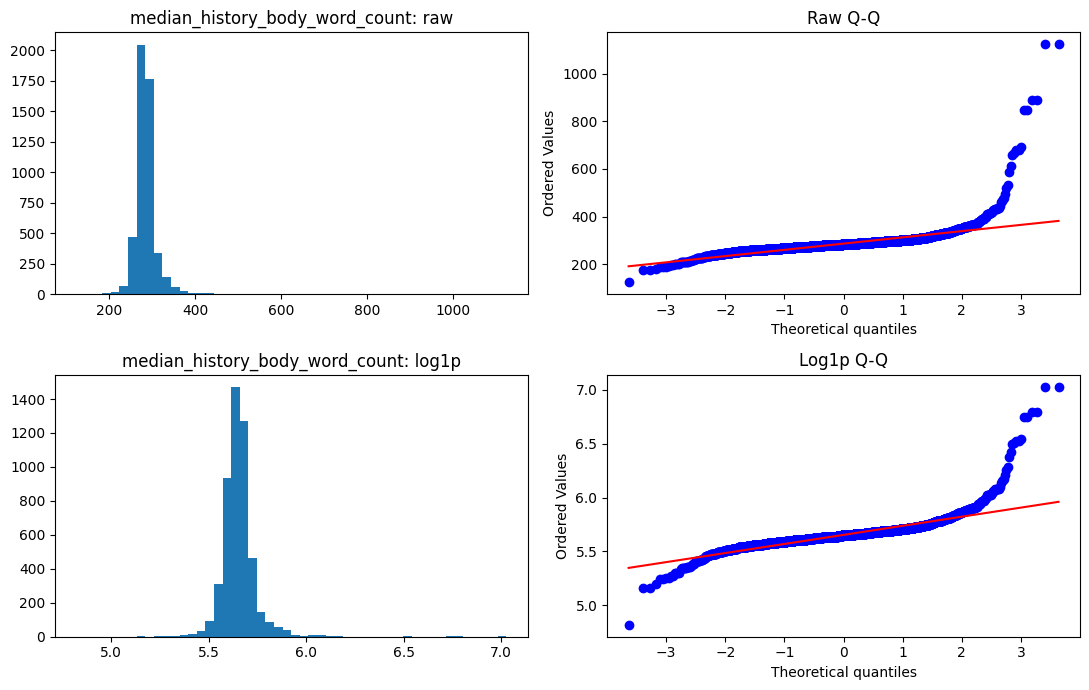

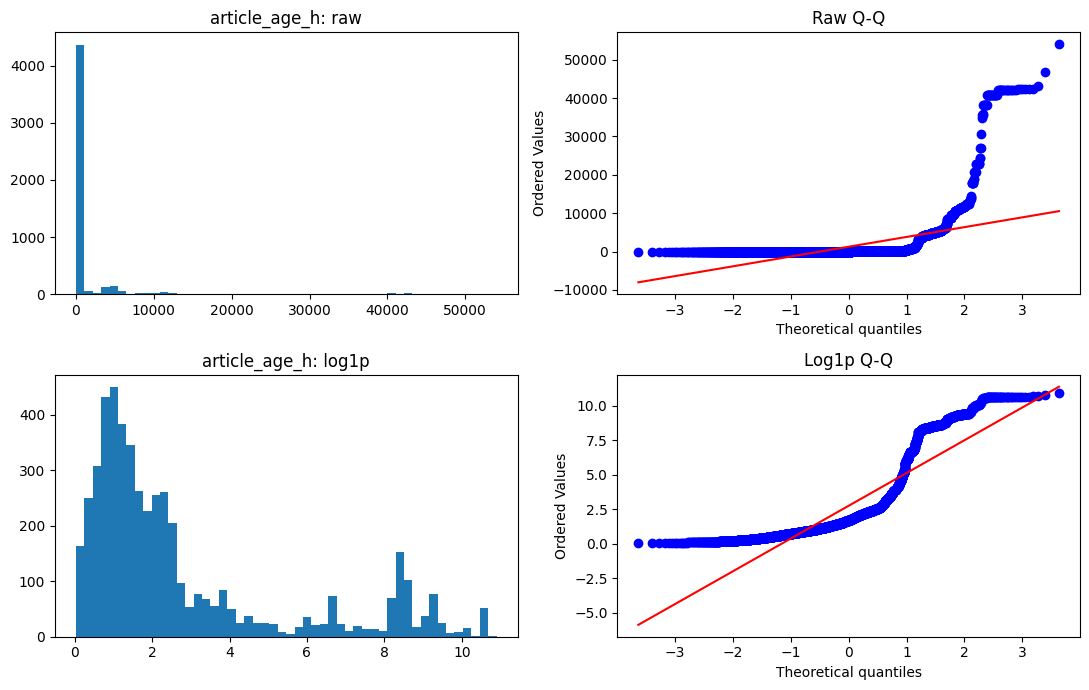

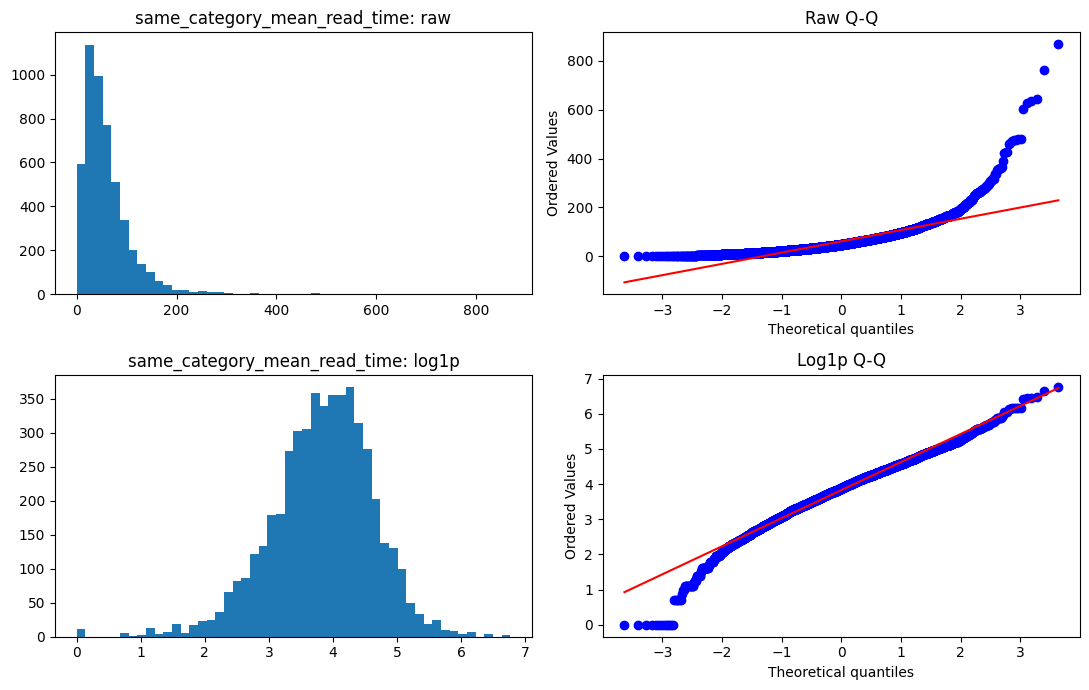

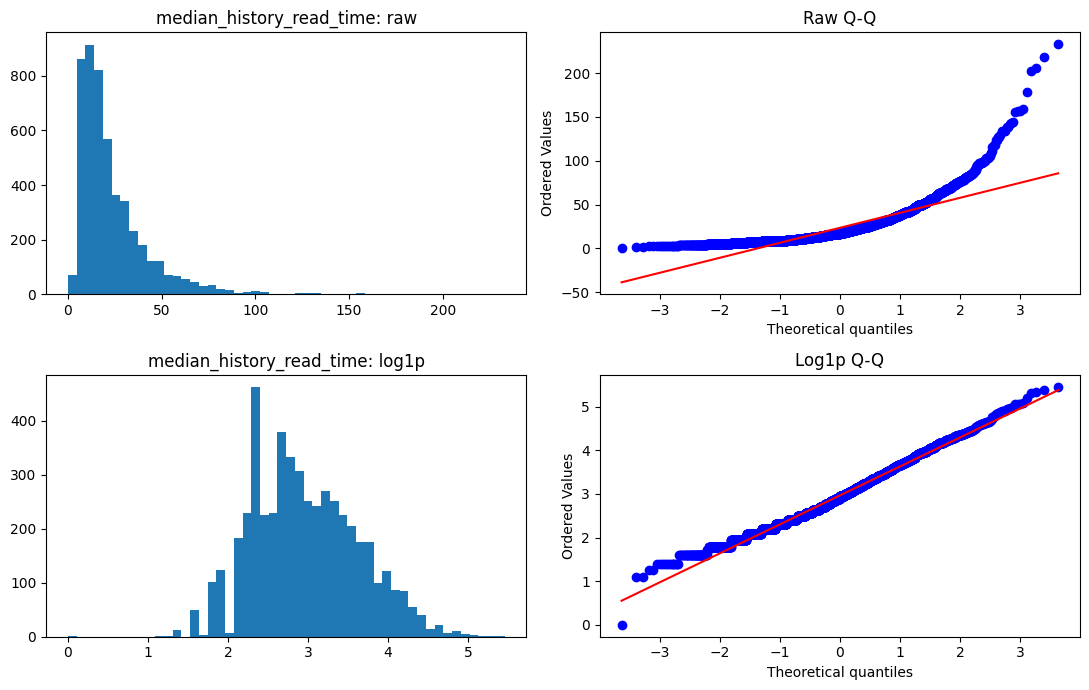

In [42]:
if not selected_log_columns:
    print("No fields met the log1p selection rule.")
else:
    for field in selected_log_columns[:4]:
        values = pd.to_numeric(train_numeric[field], errors="coerce")
        sample = values.replace([np.inf, -np.inf], np.nan).dropna()
        sample = sample.sample(n=min(len(sample), 5000), random_state=42)
        logged = np.log1p(sample)
        fig, axes = plt.subplots(2, 2, figsize=(11, 7))
        axes[0, 0].hist(sample, bins=50)
        axes[0, 0].set_title(f"{field}: raw")
        stats.probplot(sample, dist="norm", plot=axes[0, 1])
        axes[0, 1].set_title("Raw Q-Q")
        axes[1, 0].hist(logged, bins=50)
        axes[1, 0].set_title(f"{field}: log1p")
        stats.probplot(logged, dist="norm", plot=axes[1, 1])
        axes[1, 1].set_title("Log1p Q-Q")
        fig.tight_layout()
        plt.show()

## 15. Save log variants for train, validation, and test

The decision is made from train only. For the holdout update, this cell loads the existing train-selected log1p fields and applies them only to test and writes copies with extra columns under feature_engineering/log_variants/. It preserves the original feature files and the shared schema across splits. The copies contain both raw and log versions; choose one version per field when selecting predictors for a model. The saved train transform selection stays unchanged.

Scaling is a separate model-preparation choice. Standardize continuous predictors after train-fitted imputation for linear/logistic models, SVMs, or neural networks when useful; fit the scaler on train and apply it to validation/test. Tree models generally do not need scaling. Standardization changes scale, not distribution shape, so it does not make a skewed field normal.

In [ ]:
WRITE_LOG_VARIANT_FILES = True
OVERWRITE_LOG_VARIANTS = True
LOG_OUTPUT_ROOT = OUTPUT_ROOT / "log_variants"
selection_path = LOG_OUTPUT_ROOT / "log_variant_selection.json"
selected_log_columns = json.loads(selection_path.read_text())["source_fields"]

def write_log_variant_file(source_path, output_path, fields, batch_size=5_000):
    source = pq.ParquetFile(source_path)
    unavailable = set(fields) - set(source.schema_arrow.names)
    if unavailable:
        raise ValueError(f"{source_path} lacks log fields: {sorted(unavailable)}")
    if output_path.exists() and not OVERWRITE_LOG_VARIANTS:
        raise FileExistsError(f"Log-variant file exists: {output_path}")
    output_schema = pa.schema([
        *source.schema_arrow,
        *(pa.field(f"{field}_log1p", pa.float32()) for field in fields),
    ])
    with tempfile.NamedTemporaryFile(
        prefix=f".{output_path.stem}_", suffix=".parquet",
        dir=output_path.parent, delete=False
    ) as temporary:
        temporary_path = Path(temporary.name)
    try:
        with pq.ParquetWriter(temporary_path, output_schema, compression="snappy") as writer:
            for batch in source.iter_batches(batch_size=batch_size):
                frame = batch.to_pandas()
                for field in fields:
                    values = pd.to_numeric(frame[field], errors="coerce").astype("float64")
                    values = values.replace([np.inf, -np.inf], np.nan)
                    if values.lt(0).any():
                        raise ValueError(f"{source_path}: {field} contains negative values")
                    frame[f"{field}_log1p"] = np.log1p(values).astype("float32")
                writer.write_table(pa.Table.from_pandas(
                    frame.loc[:, output_schema.names],
                    schema=output_schema, preserve_index=False
                ))
        os.replace(temporary_path, output_path)
    except BaseException:
        temporary_path.unlink(missing_ok=True)
        raise
    return pq.ParquetFile(output_path).metadata.num_rows

if WRITE_LOG_VARIANT_FILES and selected_log_columns:
    LOG_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    summary = []
    for split in REBUILD_SPLITS:
        source_path = OUTPUT_ROOT / f"{split}_features.parquet"
        output_path = LOG_OUTPUT_ROOT / f"{split}_features.parquet"
        rows = write_log_variant_file(
            source_path, output_path, selected_log_columns
        )
        summary.append({
            "split": split, "rows": rows,
            "added_log_columns": len(selected_log_columns),
            "output": str(output_path),
        })
    display(pd.DataFrame(summary))
    print("Reused train-only transform selection:", selection_path)
elif WRITE_LOG_VARIANT_FILES:
    print("No log-variant files were written because no fields met the rule.")
else:
    print("WRITE_LOG_VARIANT_FILES is False; diagnostics only.")

## 16. Save a scaled copy of the log-variant datasets

The log-variant files contain every original field plus the selected log1p fields. For this holdout update, reuse the train medians and StandardScaler parameters saved in scaling_state.json. It applies those same fitted values to test and writes separate copies under feature_engineering/scaled_log_variants/. Source feature files remain available for tree models and comparisons.

Scale continuous numeric predictors, including raw and log alternatives and history preference fractions. The saved copy still contains both alternatives; select one version per source field when fitting a model. Identifiers, labels, timestamps, hour/weekday codes, booleans, and one-hot indicators keep their original values. The existing train-derived medians, means, scales, and column list in scaling_state.json stay unchanged. Scaling is optional for the eventual model; this copy is useful for scale-sensitive models.

In [ ]:
from sklearn.preprocessing import StandardScaler

SCALE_LOG_VARIANT_FILES = True
OVERWRITE_SCALED = True
SCALED_OUTPUT_ROOT = OUTPUT_ROOT / "scaled_log_variants"
LOG_TRAIN_PATH = LOG_OUTPUT_ROOT / "train_features.parquet"

if SCALE_LOG_VARIANT_FILES:
    for split in SPLITS:
        path = LOG_OUTPUT_ROOT / f"{split}_features.parquet"
        if not path.is_file():
            raise FileNotFoundError(f"Run section 15 first: {path}")

    train_schema = pq.ParquetFile(LOG_TRAIN_PATH).schema_arrow
    count_fields = {
        "slate_size", "body_word_count", "topic_count",
        "history_size", "history_clicks_7d",
    }
    non_predictors = {
        "split", "user_id", "impression_id", "candidate_article_id",
        "current_page_article_id", "impression_time", "clicked",
        "hour", "day_of_week",
    }
    scale_columns = [
        field.name for field in train_schema
        if field.name not in non_predictors
        and not field.name.startswith("ohe_")
        and (
            pa.types.is_floating(field.type)
            or field.name in count_fields
        )
    ]
    if not scale_columns:
        raise ValueError("No continuous numeric predictors were found to scale")
    for split in SPLITS:
        path = LOG_OUTPUT_ROOT / f"{split}_features.parquet"
        if pq.ParquetFile(path).schema_arrow.names != train_schema.names:
            raise ValueError(f"{split} log-variant columns differ from train")

    scaling_state = json.loads((SCALED_OUTPUT_ROOT / "scaling_state.json").read_text())
    scale_columns = scaling_state["columns"]
    impute_values = scaling_state["impute_values"]

    def continuous_matrix(frame, columns, fill_values):
        arrays = []
        for column in columns:
            values = pd.to_numeric(frame[column], errors="coerce")
            array = values.to_numpy(dtype="float64", na_value=np.nan)
            array[~np.isfinite(array)] = fill_values[column]
            arrays.append(array)
        return np.column_stack(arrays)

    scaler = StandardScaler()
    scaler.mean_ = np.asarray([scaling_state["mean"][c] for c in scale_columns])
    scaler.scale_ = np.asarray([scaling_state["scale"][c] for c in scale_columns])
    scaler.n_features_in_ = len(scale_columns)
    print(f"Reused train-only scaler on {len(scale_columns)} continuous columns")
    print("Log columns included:", [name for name in scale_columns if name.endswith("_log1p")])
    print("Boolean and one-hot columns remain 0/1")

### Write the scaled copies

Each file retains the original column names and order. The selected continuous columns now contain imputed, standardized values; their Arrow types become float32. The source log-variant Parquet files remain the reference for unscaled values.

In [ ]:
def write_scaled_file(source_path, output_path, columns, fill_values, fitted_scaler,
                      batch_size=5_000):
    source = pq.ParquetFile(source_path)
    if output_path.exists() and not OVERWRITE_SCALED:
        raise FileExistsError(f"Scaled file exists: {output_path}")
    scaled_set = set(columns)
    output_schema = pa.schema([
        pa.field(field.name, pa.float32()) if field.name in scaled_set else field
        for field in source.schema_arrow
    ])
    with tempfile.NamedTemporaryFile(
        prefix=f".{output_path.stem}_", suffix=".parquet",
        dir=output_path.parent, delete=False
    ) as temporary:
        temporary_path = Path(temporary.name)
    try:
        with pq.ParquetWriter(temporary_path, output_schema, compression="snappy") as writer:
            for batch in source.iter_batches(batch_size=batch_size):
                frame = batch.to_pandas()
                matrix = continuous_matrix(frame, columns, fill_values)
                transformed = fitted_scaler.transform(matrix).astype("float32")
                frame[columns] = pd.DataFrame(
                    transformed, columns=columns, index=frame.index
                )
                writer.write_table(pa.Table.from_pandas(
                    frame.loc[:, output_schema.names],
                    schema=output_schema, preserve_index=False
                ))
        os.replace(temporary_path, output_path)
    except BaseException:
        temporary_path.unlink(missing_ok=True)
        raise
    return pq.ParquetFile(output_path).metadata.num_rows

if SCALE_LOG_VARIANT_FILES:
    SCALED_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    scaled_summary = []
    for split in REBUILD_SPLITS:
        source_path = LOG_OUTPUT_ROOT / f"{split}_features.parquet"
        output_path = SCALED_OUTPUT_ROOT / f"{split}_features.parquet"
        rows = write_scaled_file(
            source_path, output_path, scale_columns, impute_values, scaler
        )
        scaled_summary.append({
            "split": split,
            "candidate_rows": rows,
            "scaled_columns": len(scale_columns),
            "path": str(output_path),
        })
    display(pd.DataFrame(scaled_summary))
    print("Reused train-fitted scaling state:", SCALED_OUTPUT_ROOT / "scaling_state.json")
    (OUTPUT_ROOT / "split_manifest.json").write_text(json.dumps(SPLIT_MANIFEST, indent=2) + "\n")
else:
    print("SCALE_LOG_VARIANT_FILES is False; no scaled copies were written.")